In [3]:
#1 Install required libraries
!pip install -q transformers datasets evaluate accelerate torch

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import VGG16, ResNet50, EfficientNetB0
from tensorflow.keras.layers import (
    Input, Dense, Dropout, Flatten,
    GlobalAveragePooling2D, Conv2D, MaxPooling2D
)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, classification_report

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Use smaller subsets to keep the practical manageable
x_train = x_train[:10000]
y_train = y_train[:10000]

x_test = x_test[:2000]
y_test = y_test[:2000]

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 111s 1us/step
Training images: (10000, 32, 32, 3)
Testing images: (2000, 32, 32, 3)


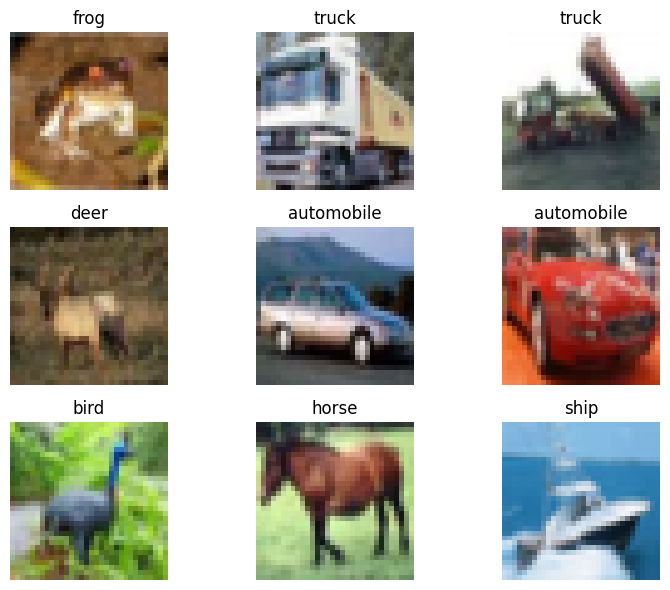

In [6]:
plt.figure(figsize=(8, 6))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
IMG_SIZE = 96
BATCH_SIZE = 32

def preprocess_images(images, labels):
    images = tf.image.resize(images, (IMG_SIZE, IMG_SIZE))
    return images, tf.cast(tf.squeeze(labels), tf.int32)

train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_ds = train_ds.shuffle(5000).map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_ds = test_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [8]:
def create_transfer_model(base_model):
    base_model.trainable = False

    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    outputs = Dense(10, activation='softmax')(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [9]:
vgg_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

vgg_model = create_transfer_model(vgg_base)
vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

resnet_model = create_transfer_model(resnet_base)
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,851,274 (90.99 MB)

 Trainable params: 263,562 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [11]:
efficient_base = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

efficient_model = create_transfer_model(efficient_base)
efficient_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,829 (16.08 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [12]:
alexnet_model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    Conv2D(96, (11, 11), strides=4, activation='relu'),
    MaxPooling2D((3, 3), strides=2),

    Conv2D(256, (5, 5), padding='same', activation='relu'),
    MaxPooling2D((3, 3), strides=2),

    Conv2D(384, (3, 3), padding='same', activation='relu'),
    Conv2D(384, (3, 3), padding='same', activation='relu'),
    Conv2D(256, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((3, 3), strides=2),

    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

alexnet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

alexnet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 22, 22, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 10, 10, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,883,914 (14.82 MB)

 Trainable params: 3,883,914 (14.82 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
models = {
    'AlexNet': alexnet_model,
    'VGG16': vgg_model,
    'ResNet50': resnet_model,
    'EfficientNetB0': efficient_model
}

results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(
        train_ds,
        epochs=2,
        verbose=1
    )

    loss, accuracy = model.evaluate(test_ds, verbose=0)
    elapsed = time.time() - start_time

    results[name] = {
        'Accuracy': accuracy,
        'Test Loss': loss,
        'Training Time (seconds)': elapsed
    }

    print(f"{name} Test Accuracy: {accuracy:.4f}")
    print(f"Training Time: {elapsed:.1f} seconds")


Training AlexNet...
Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.1010 - loss: 2.3036
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.1035 - loss: 2.3025
AlexNet Test Accuracy: 0.0975
Training Time: 25.5 seconds

Training VGG16...
Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.4461 - loss: 2.2945
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.6104 - loss: 1.1464
VGG16 Test Accuracy: 0.6495
Training Time: 26.4 seconds

Training ResNet50...
Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step - accuracy: 0.6299 - loss: 1.1042
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7459 - loss: 0.7326
ResNet50 Test Accuracy: 0.7240
Training Time: 42.9 seconds

Training EfficientNetB0...
Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 53ms/step - accuracy: 0.7606 - loss: 0.7486
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8465 - loss: 0.4626
EfficientNetB0 Test Accuracy: 0.8290
Training

In [14]:
import pandas as pd

results_df = pd.DataFrame(results).T
print(results_df)

                Accuracy  Test Loss  Training Time (seconds)
AlexNet           0.0975   2.302322                25.505044
VGG16             0.6495   1.052756                26.424428
ResNet50          0.7240   0.769772                42.926254
EfficientNetB0    0.8290   0.464748                58.974710


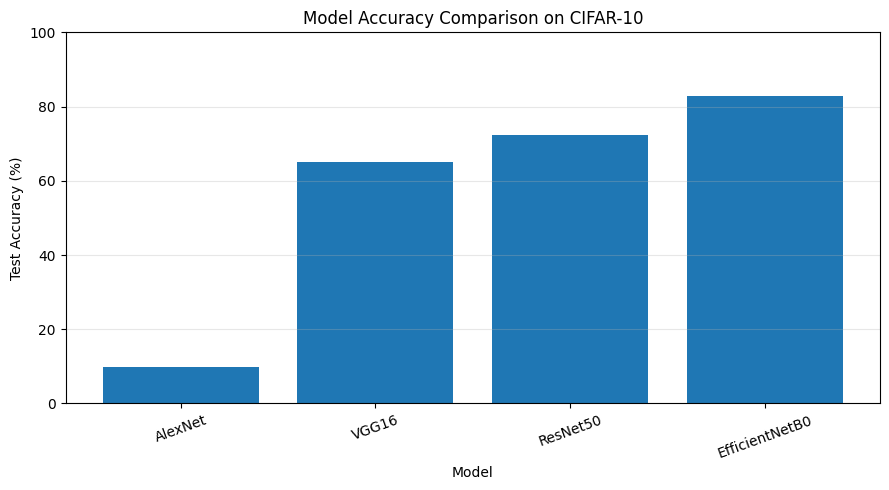

In [15]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df.index,
    results_df['Accuracy'] * 100
)

plt.title('Model Accuracy Comparison on CIFAR-10')
plt.xlabel('Model')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
best_name = results_df['Accuracy'].idxmax()
best_model = models[best_name]

print("Best model based on test accuracy:", best_name)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

Best model based on test accuracy: EfficientNetB0
              precision    recall  f1-score   support

    airplane       0.82      0.82      0.82       196
  automobile       0.94      0.89      0.91       198
        bird       0.85      0.70      0.77       195
         cat       0.69      0.68      0.69       199
        deer       0.80      0.81      0.81       198
         dog       0.74      0.79      0.76       185
        frog       0.86      0.85      0.85       216
       horse       0.81      0.91      0.86       193
        ship       0.91      0.89      0.90       217
       truck       0.87      0.93      0.90       203

    accuracy                           0.83      2000
   macro avg       0.83      0.83      0.83      2000
weighted avg       0.83      0.83      0.83      2000

